# Demographics by language region

**Goal:** Compare urban_rural, share_65plus and avg_income across language regions before modelling.

**Data:** `votes_demographics.parquet`, reduced to one row per municipality (demographics repeat for every vote).

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_parquet("../data/processed/votes_demographics.parquet")

muni = df.drop_duplicates("bfs_nr")[
    ["bfs_nr", "municipality", "canton", "language", "urban_rural", "share_65plus", "avg_income"]
]
print(df.shape, muni.shape)

(286118, 24) (2105, 7)


## Age and income

In [2]:
muni.groupby("language")[["share_65plus", "avg_income"]].agg(["count", "median", "mean", "min", "max"]).round(2)

share_65plus                          avg_income                      \
                count median  mean   min   max      count    median      mean   
language                                                                        
de               1369   0.19  0.19  0.09  0.39       1354  64285.37  66381.31   
fr                606   0.17  0.17  0.06  0.36        603  64203.84  71688.37   
it                115   0.23  0.24  0.13  0.38        114  56640.77  60122.72   
rm                 15   0.25  0.25  0.18  0.29         15  49062.19  51628.65   

                               
               min        max  
language                       
de        23925.43  260148.05  
fr        34654.65  578659.65  
it        33378.43  130797.70  
rm        45242.20   74258.27

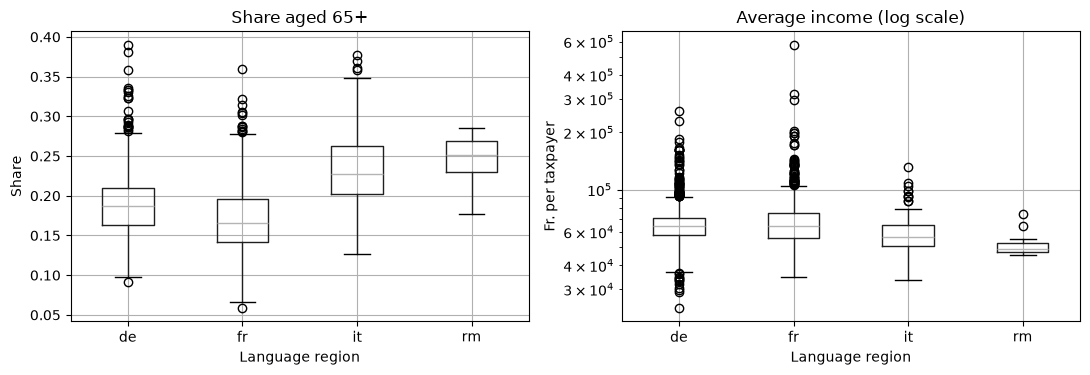

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))

muni.boxplot(column="share_65plus", by="language", ax=axes[0])
axes[0].set_title("Share aged 65+")
axes[0].set_ylabel("Share")

muni.boxplot(column="avg_income", by="language", ax=axes[1])
axes[1].set_yscale("log")
axes[1].set_title("Average income (log scale)")
axes[1].set_ylabel("Fr. per taxpayer")

for ax in axes:
    ax.set_xlabel("Language region")
fig.suptitle("")
plt.tight_layout()
plt.show()

**Finding:** 

## Missing income

In [4]:
missing = muni[muni["avg_income"].isna()]
print(missing["language"].value_counts())
missing[["bfs_nr", "municipality", "canton", "language"]]

language
de    15
fr     3
it     1
Name: count, dtype: int64


,bfs_nr,municipality,canton,language
354,708,Schelten,Bern / Berne,de
355,709,Seehof,Bern / Berne,de
358,715,Rebévelier,Bern / Berne,de
469,972,Berken,Bern / Berne,de
593,1343,Innerthal,Schwyz,de
608,1369,Riemenstalden,Schwyz,de
781,2430,Welschenrohr-Gänsbrunnen,Solothurn,de
818,2524,Hüniken,Solothurn,de
1108,3669,Tschappina,Graubünden / Grigioni / Grischun,de
1115,3711,Rongellen,Graubünden / Grigioni / Grischun,de


**Finding:** 

## Urban / rural

In [5]:
pd.crosstab(muni["language"], muni["urban_rural"], margins=True)

urban_rural,intermediate,rural,urban,All
language,,,,
de,401,625,343,1369
fr,150,335,121,606
it,28,42,45,115
rm,1,14,0,15
All,580,1016,509,2105


In [6]:
(pd.crosstab(muni["language"], muni["urban_rural"], normalize="index") * 100).round(1)

urban_rural,intermediate,rural,urban
language,,,
de,29.3,45.7,25.1
fr,24.8,55.3,20.0
it,24.3,36.5,39.1
rm,6.7,93.3,0.0


**Finding:** 